**Seda Kart**

General Research Project

**Generative AI Declaration**

Claude (Anthropic) was used to write and debug code in this notebook and to improve figures. Decisions on cohort design, model selection, and treatment of class imbalance were made by the project team. All code was checked and executed by me before its outputs were used in the report. Full AI use declaration can be found in the report.

# Phase 2: Cohort Classification

**Project:** Student Dropout Survival Analysis (Bayes 26D)
**Random seed:** 42 (fixed for every split, model, resampling and search call)

## What this notebook does

Phase 1 created four cohorts, each in a with-engagement and no-engagement variant, and saved the eight datasets to data/processed/. This notebook models each cohort separately. Cohorts 1 to 3 predict whether a student progresses beyond the current checkpoint; Cohort 4 predicts the final provider outcome among students with complete recorded assessment blocks.
A cohort is the set of students still present at one checkpoint. The target records progression for Cohorts 1 to 3 and the final dropout outcome for Cohort 4.

## The method

- Five classifiers, running from simple to flexible, are fitted to every cohort.
- Three approaches to class imbalance are screened at library defaults: no correction, class weights, and SMOTE.
- The two that survive screening, no correction and class weights, are then tuned exhaustively for every distinct model–method combination in every cohort. Gradient Boosting's weighted combination is not repeated because the model has no class_weight parameter.
- Each cohort's winner is the highest tuned cross-validated F1 on the dropout class, measured on the training split alone.
- Model selection and tuning use cross-validation on the training split only. Final test metrics are then reported on a held-out split that played no part in selection or tuning.
- A seed-stability check tests whether each winning score depends on the random seed, and an engagement comparison measures how far each result rests on the amortised engagement columns.

**Consumes:** `data/processed/cohort_{1..4}.parquet` and `cohort_{1..4}_noeng.parquet`
**Produces:** metric tables in `outputs/tables/`, figures in `outputs/figures/`, and the selected model per cohort in `models/`.

## Resumable runs

Every fitted result is cached under `data/processed/_cache_v1/`. Re-running re-uses finished results and computes only what is missing. Delete that folder to retrain from scratch.

## 2.0 Setup and load

All libraries are imported in one place. `imbalanced-learn` provides SMOTE and a `Pipeline` wrapper that keeps resampling inside each cross-validation fold, so no validation fold sees synthetic minority samples.

The per-cohort target columns are defined next, every Phase 1 output file is confirmed present before any training begins, and all eight files are loaded: four cohorts by two variants. For Cohorts 1 to 3, the drop rate is the share that does not progress beyond the checkpoint. For Cohort 4, it is the share labelled dropout = Y among lifespan-4 students, and it is the minority class the models have to detect.

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, GridSearchCV,
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay,
    make_scorer,
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', palette='husl')

SEED      = 42
TEST_SIZE = 0.20
CV_FOLDS  = 5

DATA_DIR  = Path('data/processed')
FIG_DIR   = Path('outputs/figures')
TABLE_DIR = Path('outputs/tables')
MODEL_DIR = Path('models')
CACHE_DIR = DATA_DIR / '_cache_v1'          # resumable-run cache for this notebook

for d in [FIG_DIR, TABLE_DIR, MODEL_DIR, CACHE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Each cohort's binary target (1 = survives to next checkpoint, 0 = dropout = minority)
TARGETS = {
    1: 'survives_phase_1',
    2: 'survives_phase_2',
    3: 'survives_phase_3',
    4: 'survives_to_certificate',
}

COHORT_LABELS = {
    1: 'Cohort 1 (after Test 1, n=18,724)',
    2: 'Cohort 2 (after Test 2, n=17,512)',
    3: 'Cohort 3 (after Test 3, n=15,207)',
    4: 'Cohort 4 (certificate, n=13,632)',
}

ENGAGEMENT_COLS = ['forum Q', 'forum A', 'office hour visits']

# The cohort files are consumed exactly as Phase 1 produced them: amortised engagement,
# decimal tell intact. Section 2.2 shows the pattern and explains why the data is kept as-is.
for i in range(1, 5):
    for suffix in ('', '_noeng'):
        path = DATA_DIR / f'cohort_{i}{suffix}.parquet'
        assert path.exists(), f'Missing Phase 1 output: {path}'

print(f'Seed: {SEED}  |  Test fraction: {TEST_SIZE:.0%}  |  CV folds: {CV_FOLDS}')
print('All Phase 1 cohort files confirmed present. Ready to train.\n')

cohorts_eng   = {}   # amortised-engagement variants
cohorts_noeng = {}   # engagement-dropped variants

print(f"{'Cohort':<40} {'Shape':>12}  {'Dropouts':>9}  {'Drop rate':>10}")
print('-' * 78)
for i in range(1, 5):
    cohorts_eng[i]   = pd.read_parquet(DATA_DIR / f'cohort_{i}.parquet')
    cohorts_noeng[i] = pd.read_parquet(DATA_DIR / f'cohort_{i}_noeng.parquet')
    t = TARGETS[i]
    n_drop = (cohorts_eng[i][t] == 0).sum()
    print(f'  {COHORT_LABELS[i]:<38} {str(cohorts_eng[i].shape):>12}  {n_drop:>8}   '
          f'{n_drop / len(cohorts_eng[i]) * 100:>8.1f}%')
print('-' * 78)
print('Minority class = dropout (coded 0) in every cohort.')

Seed: 42  |  Test fraction: 20%  |  CV folds: 5
All Phase 1 cohort files confirmed present. Ready to train.

Cohort                                          Shape   Dropouts   Drop rate
------------------------------------------------------------------------------
  Cohort 1 (after Test 1, n=18,724)        (18724, 9)      1212        6.5%
  Cohort 2 (after Test 2, n=17,512)       (17512, 12)      2305       13.2%
  Cohort 3 (after Test 3, n=15,207)       (15207, 14)      1575       10.4%
  Cohort 4 (certificate, n=13,632)        (13632, 18)      2455       18.0%
------------------------------------------------------------------------------
Minority class = dropout (coded 0) in every cohort.


## 2.1 Framing: four problems, not one

The naive approach would fit one classifier to all 18,724 students with `dropout` as the target. But students who left early have every later column missing, so that model would have to impute values never collected or discard the 5,092 incomplete rows, 27.2% of the data.

The cohort design avoids both. Each cohort asks a local question on complete data.

| Cohort | Question | Students | Drop here |
|---|---|---|---|
| 1 | Does the student get past Test 1? | 18,724 | 1,212 (6.5%) |
| 2 | Does the student get past Test 2? | 17,512 | 2,305 (13.2%) |
| 3 | Does the student get past Test 3? | 15,207 | 1,575 (10.4%) |
| 4 | Does the student certify? | 13,632 | 2,455 (18.0%) |

Source: Phase 1 cohort files. Drop rate is the share of that cohort, not of all students.

Each cohort is its own learning problem, with its own class imbalance, feature set and difficulty. Early cohorts have many students and few features; late cohorts have fewer students and more features. Which model type suits which end of that scale is an empirical question, so all five are fitted to all four cohorts and selected per cohort.

## 2.2 Whole numbers in the engagement features

Phase 1 amortises each student's engagement totals across the phases they were present for: for lifespan `k`, the value in cohort `j` is `total / k * j`. In a student's final cohort this becomes `total / k * k`, which returns the total exactly, so the value is whole. In earlier cohorts it is whole only when the division comes out even.

The rule below reads nothing but the decimals, ignoring every grade and attendance figure, and is scored on the dropout class.

Recall is 1.000 by construction rather than by discovery. Every dropout is in their final cohort, so their values are always whole and the rule always predicts dropout for them. Precision is the informative column.

Cohort 4 is the exception. It contains only students with lifespan 4, since everyone else has already left, so the divisor is the same for all of them and every value is whole. The rule predicts dropout for the entire cohort and its precision reduces to the cohort's dropout rate. That row measures nothing about the pattern. The rule discriminates only where lifespan varies within the cohort, which is Cohorts 1 to 3.

Two things temper the reading. Students with zero engagement across all three columns are marked whole in every cohort, since `0 / k * j` is always zero, and their disengagement is behavioural rather than arithmetic. And the rule could not be used in practice: a live system does not know a student's lifespan, which is the thing it is trying to predict.

These figures matter when the fitted results are read. A model that scores near the rule in a given cohort may be reading the same arithmetic rather than the students' behaviour.

In [2]:
def decimal_rule_score(df, target_col):
    """Scoring a rule that predicts dropout when all three engagement values are whole."""
    whole = (df[ENGAGEMENT_COLS] % 1 == 0).all(axis=1)
    actual_dropout = (df[target_col] == 0)

    tp = (whole & actual_dropout).sum()
    fp = (whole & ~actual_dropout).sum()
    fn = (~whole & actual_dropout).sum()

    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return precision, recall, f1


print('Whole-number rule, reading only the engagement decimals\n')
print(f"{'Cohort':<12}{'Precision':>11}{'Recall':>9}{'F1':>8}")
for i in range(1, 5):
    p, r, f = decimal_rule_score(cohorts_eng[i], TARGETS[i])
    note = '   uninformative: every student in Cohort 4 has lifespan 4' if i == 4 else ''
    print(f'  Cohort {i}{p:>12.3f}{r:>9.3f}{f:>8.3f}{note}')

Whole-number rule, reading only the engagement decimals

Cohort        Precision   Recall      F1
  Cohort 1       0.629    1.000   0.772
  Cohort 2       0.573    1.000   0.729
  Cohort 3       0.886    1.000   0.939
  Cohort 4       0.180    1.000   0.305   uninformative: every student in Cohort 4 has lifespan 4


### What the pattern means, and why the data is left unchanged

The rule scores high in Cohorts 1 to 3 while knowing nothing about behaviour, so the whole-number pattern alone tracks dropout there. In Cohort 4 it collapses to the base rate, because lifespan is constant within that cohort and the rule has nothing to separate.

Two readings are available. On one, the pattern is behavioural: a student who asked many questions early and then left had no later chance to ask, so their concentrated early activity is real and worth learning from. On the other, it is arithmetic: the whole number follows from `total / k * k` and says nothing about the student.

Both are partly right, and they cannot be separated with the data available. A held-out test split does not resolve it, since the same construction is present in training and test data alike.

The engagement columns are kept regardless. They are fully populated for every student, and removing them would discard a known contribution to eliminate an artefact of unknown size. The data is therefore left exactly as Phase 1 produced it: no rounding, no workaround, and no separate treatment for Cohort 4. Modifying the features would change what the models see without establishing which reading is correct. The rule's scores are reported openly instead, and the engagement comparison in Section 2.8 measures how far each cohort's performance rests on these columns.

## 2.3 Candidate models and evaluation metrics

### The five candidates

Five classifiers are fitted, spanning the range from interpretable to flexible. The same five run on every cohort.

| Model | Why included |
|---|---|
| Logistic regression | The linear baseline; its coefficients are readable directly. |
| Decision tree | Captures threshold effects and stays interpretable. |
| Random forest | Averaging many trees gives more stable predictions than one. |
| Gradient boosting | Frequently the strongest method on tabular data. |
| SVM (RBF kernel) | A model family unlike the others, and one with few settings to tune. |

Logistic regression and the SVM depend on feature scale, so standardisation happens inside their pipelines; the tree models do not need it. The SVM runs with `probability=False`, since its internal calibration cross-validation is the slowest step in the whole search and the ranking metrics use its `decision_function` scores instead.

One asymmetry is unavoidable. Scikit-learn's gradient boosting has no `class_weight` parameter, so for that model the weighted method is identical to no correction and only one of the two is computed. Gradient boosting therefore competes without the class-weight option available to the other four.

### The metrics reported

Every fitted model records cross-validated F1 and its standard deviation on the training split, then accuracy, precision, recall, F1, ROC-AUC, PR-AUC and a confusion matrix on the held-out test split. The target codes survival as 1 and dropout as 0, and precision, recall, F1 and PR-AUC are all computed on the zero class, since identifying dropouts is the objective.

| Metric | Role here |
|---|---|
| Accuracy | Reported for completeness, never used to select. |
| Precision | Cost of false alarms. |
| Recall | Cost of missed at-risk students. |
| F1 | The selection metric. |
| ROC-AUC | Probability a random dropout is rated above a random survivor; 0.5 is chance. |
| PR-AUC | The same idea on the rare class alone, so it responds more sharply to imbalance. |
| Confusion matrix | The raw counts behind the rates above. |

F1 on the dropout class selects the winner. Dropouts are the minority in every cohort, so a model predicting that everyone survives would approximately 82% accuracy in all four while catching none of them. F1 on the minority class penalises exactly that. In a retention setting recall arguably matters more than precision, since a missed at-risk student costs more than a false alarm, but F1 balances the two and is the established choice for classification under imbalance.

### Model pipelines and helper functions

`make_pipeline(model, method)` returns a fresh, unfitted pipeline for any of the five models under any of the three class-imbalance methods described in Section 2.4. `canonical()` collapses the one redundant combination: gradient boosting has no `class_weight`, so its weighted run is identical to its uncorrected one and only the latter is computed. A small disk cache, `run_or_load`, makes the notebook safe to interrupt and resume.

In [3]:
MODEL_NAMES = [
    'Logistic Regression',
    'Decision Tree',
    'Random Forest',
    'Gradient Boosting',
    'SVM (RBF)',
]

# The three class-imbalance methods, described in Section 2.4. These string values are embedded in the cache tags, so they are fixed: renaming one would orphan its cached runs.
IMBALANCE_METHODS = ['none', 'weights', 'smote']


def make_pipeline(model_name, method):
    # Building a fresh pipeline for one model under one imbalance method
    steps = []
    if method == 'smote':
        steps.append(('smote', SMOTE(random_state=SEED)))
    cw = 'balanced' if method == 'weights' else None

    if model_name == 'Logistic Regression':
        steps += [('scaler', StandardScaler()),
                  ('clf', LogisticRegression(C=1.0, class_weight=cw, max_iter=1000,
                                             random_state=SEED))]
    elif model_name == 'Decision Tree':
        steps += [('clf', DecisionTreeClassifier(max_depth=10, class_weight=cw,
                                                 random_state=SEED))]
    elif model_name == 'Random Forest':
        steps += [('clf', RandomForestClassifier(n_estimators=100, class_weight=cw,
                                                 random_state=SEED, n_jobs=1))]
    elif model_name == 'Gradient Boosting':
        # No class_weight parameter exists for this model, so under 'weights' it trains
        # uncorrected, identically to 'none'.
        steps += [('clf', GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                                     max_depth=3, random_state=SEED))]
    elif model_name == 'SVM (RBF)':
        # probability=False avoids the internal calibration CV, which is the slowest step
        # in the search; decision_function supplies the ranking scores instead.
        steps += [('scaler', StandardScaler()),
                  ('clf', SVC(kernel='rbf', C=1.0, gamma='scale', class_weight=cw,
                              probability=False, cache_size=500, random_state=SEED))]
    else:
        raise ValueError(f'Unknown model: {model_name}')
    return ImbPipeline(steps)


def canonical(model_name, method):
    # Collapsing the one redundant combination onto the run that is computed
    if model_name == 'Gradient Boosting' and method == 'weights':
        method = 'none'
    return (model_name, method)


DISTINCT_COMBOS = sorted({canonical(m, meth) for m in MODEL_NAMES for meth in IMBALANCE_METHODS})


def get_scores(pipe, X):
    # Returning a per-student score, higher meaning more likely to survive.
    if hasattr(pipe[-1], 'predict_proba'):
        return pipe.predict_proba(X)[:, 1]
    return pipe.decision_function(X)


def split_cohort(df, target_col):
    # he one stratified train/test split used everywhere, at the fixed seed
    X = df.drop(columns=[target_col])
    y = df[target_col]
    return train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)


def run_or_load(tag, compute_fn):
    # Loading a finished result from the disk cache, or computing and caching it
    path = CACHE_DIR / f'{tag}.pkl'
    if path.exists():
        return joblib.load(path)
    result = compute_fn()
    joblib.dump(result, path)
    return result


def safe(name):
    return name.replace(' ', '_').replace('(', '').replace(')', '').lower()


F1_DROPOUT = make_scorer(f1_score, pos_label=0)   # primary metric: F1 on the dropout class

print(f'{len(MODEL_NAMES)} models x {len(IMBALANCE_METHODS)} imbalance methods, '
      f'{len(DISTINCT_COMBOS)} distinct runs per cohort after removing one duplicate')
print('(Gradient Boosting has no class_weight, so its "weights" run duplicates its "none" run.)')

5 models x 3 imbalance methods, 14 distinct runs per cohort after removing one duplicate
(Gradient Boosting has no class_weight, so its "weights" run duplicates its "none" run.)


### The evaluation routines

`cv_f1()` returns cross-validated F1 on the dropout class, computed on the training split, for one model at library-default hyperparameters. It builds the screening comparison in Section 2.4. `full_eval()` fits on the training split and reports the full metric suite on the untouched test split; those are the figures quoted throughout. Section 2.5 adds a third routine, `tune_combo()`, which selects each cohort's winner.

Keeping the three separate is what allows selection to happen on cross-validation while every reported figure stays on held-out data.

In [4]:
def cv_f1(df, target_col, model_name, method):
    # Cross-validated F1 on the dropout class, computed on the training split only.
    X_train, X_test, y_train, y_test = split_cohort(df, target_col)
    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    scores = cross_val_score(make_pipeline(model_name, method), X_train, y_train,
                             cv=cv, scoring=F1_DROPOUT, n_jobs=-1)
    return {'cv_mean': float(scores.mean()), 'cv_std': float(scores.std())}


def full_eval(df, target_col, model_name, method, pipe=None):
    # Fitting on the training split and reporting the full metric suite on the test split.
    # A pipe passed in, such as a tuned pipeline, is used as given.
    X_train, X_test, y_train, y_test = split_cohort(df, target_col)
    if pipe is None:
        pipe = make_pipeline(model_name, method)

    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring=F1_DROPOUT, n_jobs=-1)

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    scores = get_scores(pipe, X_test)

    clf = pipe[-1]
    if hasattr(clf, 'feature_importances_'):
        importances = clf.feature_importances_
    elif hasattr(clf, 'coef_'):
        importances = np.abs(clf.coef_[0])
    else:
        importances = None

    return {
        'Model':        model_name,
        # 'Treatment' is the field name in the on-disk cache, left unchanged so cached
        # results stay readable. Everything the notebook displays says "method".
        'Treatment':    method,
        'CV F1':        round(float(cv_scores.mean()), 3),
        'CV F1 std':    round(float(cv_scores.std()), 3),
        'Accuracy':     round(accuracy_score(y_test, y_pred), 3),
        'Precision':    round(precision_score(y_test, y_pred, pos_label=0, zero_division=0), 3),
        'Recall':       round(recall_score(y_test, y_pred, pos_label=0, zero_division=0), 3),
        'F1':           round(f1_score(y_test, y_pred, pos_label=0, zero_division=0), 3),
        'ROC-AUC':      round(roc_auc_score(y_test, scores), 3),
        'PR-AUC':       round(average_precision_score((y_test == 0).astype(int), -scores), 3),
        '_cm':          confusion_matrix(y_test, y_pred),
        '_scores':      scores.astype(np.float32),
        '_features':    list(X_train.columns),
        '_importances': importances,
        '_pipe':        pipe,
    }

print('cv_f1() and full_eval() defined.')

cv_f1() and full_eval() defined.


## 2.4 Class-imbalance handling

Dropouts are the minority in every cohort, so how the imbalance is handled is a real choice. Three standard methods are screened rather than assumed.

| Method | What it does |
|---|---|
| `none` | No correction at all. |
| `weights` | `class_weight='balanced'`, penalising minority mistakes more heavily. |
| `smote` | Synthetic minority oversampling, applied inside the training fold only. |

Because selection uses F1 on the dropout class rather than accuracy (Section 2.3), `none` is a legitimate candidate. A model that ignores dropouts is punished by the metric, so no correction can win only by detecting dropouts genuinely. No method is correct in advance, so all three are compared and the best is chosen per cohort from the evidence.

The screening below scores all five models under all three methods at library-default hyperparameters, using cross-validated F1 on the training split. Its purpose is to decide which methods are worth carrying into the full tuning in Section 2.5, not to pick a winner. Gradient boosting has no `class_weight`, so its `weights` cell duplicates its `none` cell exactly; `canonical()` computes it once and the table marks that cell rather than repeating the number.

In [5]:
print('Screening: cross-validated F1 on the dropout class at library defaults, '
      'all five models under all three methods\n')
t0 = time.time()

screening_tables = {}   # cohort -> DataFrame (5 models x 3 methods, library defaults)
default_cv       = {}   # cohort -> {(model, method): raw CV F1}, re-used in Section 2.5

for i in range(1, 5):
    runs = {}
    for (m, meth) in DISTINCT_COMBOS:
        runs[(m, meth)] = run_or_load(
            f'cv_c{i}_{meth}_{safe(m)}',
            lambda ci=i, dm=m, dt=meth: cv_f1(cohorts_eng[ci], TARGETS[ci], dm, dt)
        )['cv_mean']
    default_cv[i] = {(m, meth): runs[canonical(m, meth)]
                     for m in MODEL_NAMES for meth in IMBALANCE_METHODS}

    # Building the CSV table, rows as models and columns as methods, plus a display copy
    # that marks gradient boosting's 'weights' cell as a duplicate of its 'none' cell.
    tab = pd.DataFrame({meth: {m: round(default_cv[i][(m, meth)], 3) for m in MODEL_NAMES}
                        for meth in IMBALANCE_METHODS})
    tab.index.name = 'Model'
    screening_tables[i] = tab
    tab.to_csv(TABLE_DIR / f'grid_default_cohort{i}.csv')

    disp = pd.DataFrame({meth: {m: f'{default_cv[i][(m, meth)]:.3f}' for m in MODEL_NAMES}
                         for meth in IMBALANCE_METHODS})
    disp.index.name = 'Model'
    disp.loc['Gradient Boosting', 'weights'] = '= none'

    # The screening's one question: is SMOTE ever worth the cost of tuning it?
    lead  = max(default_cv[i][(m, meth)] for m in MODEL_NAMES for meth in ('none', 'weights'))
    smote = max(default_cv[i][(m, 'smote')] for m in MODEL_NAMES)

    print(f'=== {COHORT_LABELS[i]} ===')
    print('  ' + disp.to_string().replace('\n', '\n  '))
    print(f'  best without SMOTE {lead:.3f}   best with SMOTE {smote:.3f}   '
          f'-> SMOTE behind by {lead - smote:.3f}\n')

print(f'Done in {time.time() - t0:.0f}s.')

Screening: cross-validated F1 on the dropout class at library defaults, all five models under all three methods

=== Cohort 1 (after Test 1, n=18,724) ===
                        none weights  smote
  Model                                    
  Logistic Regression  0.508   0.432  0.454
  Decision Tree        0.931   0.893  0.771
  Random Forest        0.951   0.957  0.871
  Gradient Boosting    0.957  = none  0.819
  SVM (RBF)            0.692   0.649  0.681
  best without SMOTE 0.957   best with SMOTE 0.871   -> SMOTE behind by 0.085

=== Cohort 2 (after Test 2, n=17,512) ===
                        none weights  smote
  Model                                    
  Logistic Regression  0.363   0.513  0.517
  Decision Tree        0.907   0.884  0.906
  Random Forest        0.956   0.967  0.960
  Gradient Boosting    0.924  = none  0.901
  SVM (RBF)            0.889   0.871  0.879
  best without SMOTE 0.967   best with SMOTE 0.960   -> SMOTE behind by 0.007

=== Cohort 3 (after Test 3, n

### What the screening showed, and why only two methods are tuned

SMOTE never leads a cohort. Its best cell trails each cohort's best uncorrected or weighted cell by 0.085, 0.007, 0.028 and 0.004. The damage is concentrated in Cohort 1, where the tree models already separate the classes almost perfectly: gradient boosting falls from 0.957 to 0.819 and the decision tree from 0.931 to 0.771. Synthetic minority points near an already clean boundary mostly add noise. SMOTE does edge ahead in two of the twenty model-by-cohort cells, logistic regression in Cohort 2 at 0.517 against 0.513 and gradient boosting in Cohort 4 at 0.571 against 0.555, but both sit well behind their own cohort's leader.

SMOTE is therefore screened but not tuned, and the reason is cost. Resampling inside every fold roughly doubles the runtime of the search, and the tuning in Section 2.5 is already the most expensive part of the notebook. Spending that on a method that leads nowhere at defaults is not a good use of it.

This is a decision about scope rather than a proof. A tuned SMOTE pipeline could behave differently from the default one screened here, and the Cohort 4 margin of 0.004 is too small for the ordering there to mean anything. What the screening establishes is that SMOTE shows no advantage worth the cost, not that no advantage exists.

Class weights earn their place. In Cohort 4, the one cohort where the signal is weak, they lift every model that can use them: logistic regression from 0.389 to 0.465, the decision tree from 0.532 to 0.563, the SVM from 0.567 to 0.581, and the random forest from 0.592 to 0.593. The largest single effect anywhere in the table is elsewhere, though: logistic regression in Cohort 2 gains 0.150, from 0.363 to 0.513. Weights help where a model is struggling and do little where it is not, which is a reason to carry them forward rather than to assume them. Both `none` and `weights` therefore go into tuning, and the tuned scores decide between them.

## 2.5 Hyperparameter tuning and model selection

Comparing models at their shipped defaults compares scikit-learn's defaults, not the model families. A model can lose because its library defaults happen to suit this data less well. Every model is therefore tuned first, under each of the two methods carried forward from Section 2.4, and each cohort's winner is chosen from the tuned scores.

Each search is a full `GridSearchCV` over the grids below, with the imbalance method held fixed and CV F1 on the dropout class as the objective. It reuses the same training split and the same folds as the Section 2.4 screening, so the two tables compare directly.

**Why search the whole grid.** The grids are small lists of discrete values, 14 to 288 points, and cheap enough to search in full. Random sampling would return a subset of those same points. It cannot propose a setting the grid does not contain, nor explore the space between values.

**The default-in-grid guarantee.** Each model's library-default configuration is itself a point in its own grid, asserted in the code rather than claimed, and the search reuses the screening's folds. No tuned score can therefore fall below its screening counterpart. This holds by construction rather than by a check afterwards, and the selection loop asserts it on all forty compared cells.

**Selection.** Each cohort's winner is the highest tuned CV F1 across the nine distinct model-by-method combinations. Selection uses cross-validated scores on the training split only; the test split plays no part.

**On the grids that were not widened.** Logistic regression keeps 14 points and the decision tree keeps 150. Time is not the reason, since both are the cheapest models here. At screening, logistic regression trailed its cohort leader in every cohort: 0.508 against 0.957, 0.513 against 0.967, 0.586 against 0.974, and 0.465 against 0.593. No reachable setting was going to close gaps of that size. The SVM is given a wider grid than logistic regression's, at 36 points, because at screening it sat closest to the random forest in Cohort 4, at 0.581 against 0.593, and giving the nearest challenger a much smaller grid than its rival's would not have been a fair contest. After tuning, gradient boosting overtook it at 0.598 against the SVM's 0.586, so the closest challenger in that cohort turned out to be the model with the largest grid of all.

In [6]:
# Hyperparameter grids, searched in full. Kept to short hand-picked lists so that an
# exhaustive search stays affordable.
SEARCH_SPACES = {
    'Random Forest': {                                    # 240 points
        'clf__n_estimators':     [100, 200, 300, 400],
        'clf__max_depth':        [None, 6, 10, 16, 24],
        'clf__min_samples_leaf': [1, 2, 4, 8],
        'clf__max_features':     ['sqrt', 'log2', None],
    },
    'Gradient Boosting': {                                # 288 points
        'clf__n_estimators':     [100, 200, 300],
        'clf__learning_rate':    [0.03, 0.05, 0.1, 0.2],
        'clf__max_depth':        [2, 3, 4],
        'clf__min_samples_leaf': [1, 5, 10, 20],
        'clf__subsample':        [0.8, 1.0],
    },
    'Decision Tree': {                                    # 150 points
        # max_depth=None is deliberately absent, since a single unconstrained tree
        # memorises the training rows. Random Forest keeps None, because it controls
        # variance by averaging hundreds of trees rather than by depth, and None is
        # its own default.
        'clf__max_depth':         [4, 6, 8, 10, 12],
        'clf__min_samples_leaf':  [1, 5, 10, 20, 50],
        'clf__min_samples_split': [2, 10, 20],
        'clf__max_features':      ['sqrt', None],
    },
    'Logistic Regression': {                              # 14 points
        'clf__C':      [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
        'clf__solver': ['lbfgs', 'liblinear'],
    },
    'SVM (RBF)': {                                        # 36 points
        # Wider than the other non-winners: at screening the SVM sat closest to Random
        # Forest in Cohort 4 (0.581 against 0.593), so it needs a comparable search to
        # be a fair test. C is capped at 10, since larger values converge slowly on
        # Cohort 4's non-separable data.
        'clf__C':     [0.1, 0.5, 1, 2, 5, 10],
        'clf__gamma': ['scale', 'auto', 0.001, 0.01, 0.05, 0.1],
    },
}

# The methods carried into the tuning sweep. SMOTE is screened at library defaults in
# Section 2.4 but not tuned: it never leads a cohort, and resampling inside every fold
# would roughly double the cost of the exhaustive search below.
TUNED_METHODS = ['none', 'weights']
DISTINCT_TUNED_COMBOS = sorted({canonical(m, meth)
                                for m in MODEL_NAMES for meth in TUNED_METHODS})


def default_point(model_name):
    # Reading the library-default configuration back out of make_pipeline.
    # Taken from the pipeline itself rather than restated here, so it cannot drift if a
    # default changes above.
    params = make_pipeline(model_name, 'none').get_params()
    return {k: params[k] for k in SEARCH_SPACES[model_name]}


# The guarantee the tuned comparison rests on: every grid contains its own model's default,
# so an exhaustive search can never score below the default. Check it rather than claim it.
for _m, _space in SEARCH_SPACES.items():
    for _k, _v in default_point(_m).items():
        assert _v in _space[_k], f'{_m}: default {_k}={_v!r} is not a point in its grid'


def tune_combo(df, target_col, model_name, method):
    # Exhaustive GridSearchCV for one model and method, filling one cell of the tuned table.
    # Uses the same split and folds as cv_f1(), so the screening and tuned tables compare
    # directly and the tuned-at-least-default guarantee holds.
    X_train, X_test, y_train, y_test = split_cohort(df, target_col)
    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    search = GridSearchCV(
        make_pipeline(model_name, method), SEARCH_SPACES[model_name],
        scoring=F1_DROPOUT, cv=cv, n_jobs=-1, refit=True,
    )
    search.fit(X_train, y_train)
    return {
        'best_params':  search.best_params_,
        'best_cv_raw':  float(search.best_score_),
        'best_pipe':    search.best_estimator_,
        'n_candidates': len(search.cv_results_['params']),
    }


print('Grids searched (exhaustive; every grid contains its model default):\n')
for m in MODEL_NAMES:
    n = int(np.prod([len(v) for v in SEARCH_SPACES[m].values()]))
    print(f'  {m:<22} {n:>4} points')
    for k, v in SEARCH_SPACES[m].items():
        print(f'{"":<24}{k.replace("clf__", ""):<20}{v}')
    print()
print(f'{len(DISTINCT_TUNED_COMBOS)} distinct model x method combinations tuned per cohort '
      f'({" and ".join(TUNED_METHODS)}).')
print('All five grids contain their model default -- tuning cannot score below default.')

Grids searched (exhaustive; every grid contains its model default):

  Logistic Regression      14 points
                        C                   [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
                        solver              ['lbfgs', 'liblinear']

  Decision Tree           150 points
                        max_depth           [4, 6, 8, 10, 12]
                        min_samples_leaf    [1, 5, 10, 20, 50]
                        min_samples_split   [2, 10, 20]
                        max_features        ['sqrt', None]

  Random Forest           240 points
                        n_estimators        [100, 200, 300, 400]
                        max_depth           [None, 6, 10, 16, 24]
                        min_samples_leaf    [1, 2, 4, 8]
                        max_features        ['sqrt', 'log2', None]

  Gradient Boosting       288 points
                        n_estimators        [100, 200, 300]
                        learning_rate       [0.03, 0.05, 0.1, 0.2]
         

In [7]:
print('Tuning every model under each method, then selecting each cohort winner ...\n')
t0 = time.time()

tuned_tables   = {}   # cohort -> DataFrame (5 models x 2 methods, tuned)
WINNERS        = {}   # cohort -> (model, method), selected on tuned CV F1
winner_cv      = {}   # cohort -> winner's TUNED CV F1  (the selection score)
winner_default = {}   # cohort -> same combo's DEFAULT CV F1 (for the gain column)
tuned          = {}   # cohort -> winner's full tuning result (params, pipe, ...)

for i in range(1, 5):
    runs = {}
    for (m, meth) in DISTINCT_TUNED_COMBOS:
        runs[(m, meth)] = run_or_load(
            f'tuned_c{i}_{meth}_{safe(m)}',
            lambda ci=i, dm=m, dt=meth: tune_combo(cohorts_eng[ci], TARGETS[ci], dm, dt)
        )
    score = {(m, meth): runs[canonical(m, meth)]['best_cv_raw']
             for m in MODEL_NAMES for meth in TUNED_METHODS}

    # The invariant, checked on every cell rather than asserted in prose.
    # Each grid contains its model's default, and these scores use the same split and folds
    # as Section 2.4's screening. So no tuned cell can fall below its default.
    for k in score:
        assert score[k] >= default_cv[i][k] - 1e-9, (
            f'Cohort {i} {k}: tuned {score[k]:.4f} < default {default_cv[i][k]:.4f} -- '
            f'the grid should contain the default point on identical folds.'
        )

    # The winner: highest tuned CV F1 over the distinct model x method runs.
    # `runs` is keyed by the distinct combinations, so Gradient Boosting's duplicate
    # 'weights' entry cannot compete against its own 'none' run.
    win = max(runs, key=lambda k: runs[k]['best_cv_raw'])
    WINNERS[i]        = win
    winner_cv[i]      = runs[win]['best_cv_raw']
    winner_default[i] = default_cv[i][win]
    tuned[i]          = runs[win]

    tab = pd.DataFrame({meth: {m: round(score[(m, meth)], 3) for m in MODEL_NAMES}
                        for meth in TUNED_METHODS})
    tab.index.name = 'Model'
    tuned_tables[i] = tab
    tab.to_csv(TABLE_DIR / f'grid_tuned_cohort{i}.csv')

    disp = pd.DataFrame({meth: {m: f'{score[(m, meth)]:.3f}' for m in MODEL_NAMES}
                         for meth in TUNED_METHODS})
    disp.index.name = 'Model'
    disp.loc['Gradient Boosting', 'weights'] = '= none'

    wm, wmeth = win
    print(f'=== {COHORT_LABELS[i]} ===')
    print('  CV F1 (dropout) after exhaustive tuning')
    print('  ' + disp.to_string().replace('\n', '\n  '))
    print(f'  -> winner: {wm} / "{wmeth}"   tuned CV F1 {winner_cv[i]:.3f} '
          f'(default {winner_default[i]:.3f}, gain {winner_cv[i] - winner_default[i]:+.3f})\n')

print(f'Done in {time.time() - t0:.0f}s.')

Tuning every model under each method, then selecting each cohort winner ...

=== Cohort 1 (after Test 1, n=18,724) ===
  CV F1 (dropout) after exhaustive tuning
                        none weights
  Model                             
  Logistic Regression  0.511   0.432
  Decision Tree        0.939   0.923
  Random Forest        0.959   0.969
  Gradient Boosting    0.975  = none
  SVM (RBF)            0.827   0.791
  -> winner: Gradient Boosting / "none"   tuned CV F1 0.975 (default 0.957, gain +0.019)

=== Cohort 2 (after Test 2, n=17,512) ===
  CV F1 (dropout) after exhaustive tuning
                        none weights
  Model                             
  Logistic Regression  0.364   0.513
  Decision Tree        0.924   0.925
  Random Forest        0.958   0.969
  Gradient Boosting    0.980  = none
  SVM (RBF)            0.909   0.892
  -> winner: Gradient Boosting / "none"   tuned CV F1 0.980 (default 0.924, gain +0.056)

=== Cohort 3 (after Test 3, n=15,207) ===
  CV F1 (dropou

/opt/anaconda3/envs/grp/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


=== Cohort 4 (certificate, n=13,632) ===
  CV F1 (dropout) after exhaustive tuning
                        none weights
  Model                             
  Logistic Regression  0.390   0.465
  Decision Tree        0.549   0.563
  Random Forest        0.592   0.608
  Gradient Boosting    0.598  = none
  SVM (RBF)            0.586   0.586
  -> winner: Random Forest / "weights"   tuned CV F1 0.608 (default 0.593, gain +0.015)

Done in 8562s.


### What the tuned comparison showed

Tuning does not lift every model equally, which is why models must be tuned before they are compared. The table gives each model's gain under no correction, from its screening score to its tuned one.

| Gain from tuning | Cohort 1 | Cohort 2 | Cohort 3 | Cohort 4 |
|---|---|---|---|---|
| Logistic Regression | +0.003 | +0.001 | +0.000 | +0.001 |
| Decision Tree | +0.008 | +0.017 | +0.004 | +0.017 |
| Random Forest | +0.008 | +0.002 | +0.012 | +0.000 |
| Gradient Boosting | +0.018 | +0.056 | +0.012 | +0.043 |
| SVM (RBF) | +0.135 | +0.020 | +0.028 | +0.019 |

Random Forest gains almost nothing, 0.000 to 0.012, because scikit-learn's forest defaults are already close to the best this data offers. Gradient Boosting and the SVM gain a great deal, because their defaults are not. A comparison at library defaults therefore does not rank the model families. It ranks how well each library default happens to suit this data, and it flatters Random Forest in particular.

Cohort 2 shows what that costs. At library defaults, Random Forest scores 0.956 against Gradient Boosting's 0.924, a gap of 0.032 that looks decisive. It is not. Once tuned, Gradient Boosting reaches 0.980 while Random Forest reaches 0.969 even with class weights, and the ranking reverses. Random Forest was never the better model for Cohort 2; it merely had the better defaults. The screening gap was real, but it was measuring the wrong thing.

Cohort 4 is the one cohort that wants class weights. Random Forest with no correction gains nothing from tuning, but with class weights it reaches 0.608 and takes the cohort, edging out Gradient Boosting at 0.598. That margin of 0.010 is small, so the winner is taken as the maximum and the seed check in Section 2.7 tests whether it holds. Cohort 4 wanting a correction fits the rest of the picture: a class-weight correction lifts minority recall where the signal is weak, and Cohort 4 is the cohort whose signal is weakest.

Logistic Regression is last in every cohort and tuning cannot save it. Its largest gain anywhere is 0.003. Class weights help it more than tuning does, most visibly in Cohort 2 where it rises to 0.513 against 0.364 uncorrected, but it still finishes far behind. No theoretical defence of the model line-up is offered here: the model that predicts best in each cohort is the one reported.

In [35]:
print('Winning model per cohort, and what tuning bought:\n')
rows = []
for i in range(1, 5):
    wm, wmeth = WINNERS[i]
    gain = winner_cv[i] - winner_default[i]
    rows.append({'Cohort': f'Cohort {i}', 'Model': wm, 'Method': wmeth,
                 'Default CV F1': round(winner_default[i], 3),
                 'Tuned CV F1':   round(winner_cv[i], 3),
                 'Gain':          round(gain, 4),
                 'Candidates':    tuned[i]['n_candidates']})
    print(f'{COHORT_LABELS[i]}  ->  {wm} / {wmeth}')
    print(f'   searched {tuned[i]["n_candidates"]} candidates x {CV_FOLDS} folds')
    print(f'   default CV F1 {winner_default[i]:.3f}  ->  tuned CV F1 {winner_cv[i]:.3f}  (gain {gain:+.4f})')
    print(f'   best params: {tuned[i]["best_params"]}\n')

tuning_df = pd.DataFrame(rows).set_index('Cohort')
tuning_df.to_csv(TABLE_DIR / 'tuning_summary.csv')
print('Saved: outputs/tables/tuning_summary.csv')

Winning model per cohort, and what tuning bought:

Cohort 1 (after Test 1, n=18,724)  ->  Gradient Boosting / none
   searched 288 candidates x 5 folds
   default CV F1 0.957  ->  tuned CV F1 0.975  (gain +0.0185)
   best params: {'clf__learning_rate': 0.2, 'clf__max_depth': 3, 'clf__min_samples_leaf': 10, 'clf__n_estimators': 300, 'clf__subsample': 1.0}

Cohort 2 (after Test 2, n=17,512)  ->  Gradient Boosting / none
   searched 288 candidates x 5 folds
   default CV F1 0.924  ->  tuned CV F1 0.980  (gain +0.0559)
   best params: {'clf__learning_rate': 0.2, 'clf__max_depth': 4, 'clf__min_samples_leaf': 10, 'clf__n_estimators': 300, 'clf__subsample': 1.0}

Cohort 3 (after Test 3, n=15,207)  ->  Gradient Boosting / none
   searched 288 candidates x 5 folds
   default CV F1 0.974  ->  tuned CV F1 0.986  (gain +0.0120)
   best params: {'clf__learning_rate': 0.2, 'clf__max_depth': 3, 'clf__min_samples_leaf': 20, 'clf__n_estimators': 300, 'clf__subsample': 1.0}

Cohort 4 (certificate, n=13,

### The winners, and what tuning bought

| Cohort | Winner | Default CV F1 | Tuned CV F1 | Gain |
|---|---|---|---|---|
| 1 | Gradient Boosting / none | 0.957 | 0.975 | +0.019 |
| 2 | Gradient Boosting / none | 0.924 | 0.980 | +0.056 |
| 3 | Gradient Boosting / none | 0.974 | 0.986 | +0.012 |
| 4 | Random Forest / weights | 0.593 | 0.608 | +0.015 |

Every gain is positive by construction rather than by luck. Each grid contains its model's default, and the tuned scores use the screening's folds, so no search can return less than it started with. The loop above asserts this on all forty compared cells.

"Default" here means scikit-learn out of the box. For both winning families, every value `make_pipeline()` sets by hand, `n_estimators=100`, `learning_rate=0.1` and `max_depth=3`, matches the library's own default, and the remaining hyperparameters are left unset. The gain column therefore measures tuning against the library's general-purpose starting point, not against anything chosen for this data.

The three Gradient Boosting cohorts agree with each other. All three land on learning rate 0.2 with 300 trees at depth 3 to 4, plus a `min_samples_leaf` of 10 to 20 that stops branches fitting individual students. Three independent searches over 288 points arriving at the same corner points to a real effect rather than three lucky draws, and the diagnosis is the same in each: the default of 100 shallow trees at learning rate 0.1 underfits this data.

Cohort 4 goes the other way. Its winner constrains the forest where the default does not, capping depth at 16 and requiring 4 samples per leaf against the library's unlimited depth and single-sample leaves, while keeping the default 100 trees. Less capacity per tree and class weights pushing towards the minority: the shape expected where the signal is weak. It is also the cohort where the winner sits closest to a different model family, 0.608 against Gradient Boosting's 0.598, which is why the seed check in Section 2.7 matters more here than elsewhere.

## 2.6 Held-out test results

Selection and tuning both happened on the training split through cross-validation, described in Section 2.5. The 20% held-out test set is used for the first time here. Each cohort's winning model, tuned, is reported below with the full metric suite.

In [36]:
# Section 2.5 selected each winner from the tuned scores, and asserted on every cell that no
# tuned score falls below its default. So the reported model is simply that winner, tuned.
final = {}
for i in range(1, 5):
    wm, wmeth = WINNERS[i]
    rec = run_or_load(
        f'final_c{i}_{safe(wm)}_{wmeth}_tunedall',
        lambda ci=i, m=wm, t=wmeth, p=tuned[i]['best_pipe']: full_eval(cohorts_eng[ci], TARGETS[ci], m, t, pipe=p)
    )
    rec['Chosen'] = 'tuned'
    final[i] = rec

summary_rows = []
for i in range(1, 5):
    r = final[i]
    wm, wmeth = WINNERS[i]
    summary_rows.append({
        'Cohort':     f'Cohort {i}',
        'n students': len(cohorts_eng[i]),
        'Drop rate':  f"{(cohorts_eng[i][TARGETS[i]] == 0).mean():.1%}",
        'Best model': wm,
        'Method':     wmeth,
        'Tuned?':     r['Chosen'],
        'CV F1':      r['CV F1'],
        'Accuracy':   r['Accuracy'],
        'Precision':  r['Precision'],
        'Recall':     r['Recall'],
        'F1':         r['F1'],
        'ROC-AUC':    r['ROC-AUC'],
        'PR-AUC':     r['PR-AUC'],
    })
summary_df = pd.DataFrame(summary_rows).set_index('Cohort')
print(summary_df.to_string())
summary_df.to_csv(TABLE_DIR / 'best_model_summary.csv')
print('\nSaved: outputs/tables/best_model_summary.csv')

          n students Drop rate         Best model   Method Tuned?  CV F1  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC
Cohort                                                                                                                       
Cohort 1       18724      6.5%  Gradient Boosting     none  tuned  0.975     0.997      0.960   0.992  0.976    1.000   0.994
Cohort 2       17512     13.2%  Gradient Boosting     none  tuned  0.980     0.994      0.968   0.987  0.977    1.000   0.998
Cohort 3       15207     10.4%  Gradient Boosting     none  tuned  0.986     0.998      0.987   0.990  0.989    1.000   1.000
Cohort 4       13632     18.0%      Random Forest  weights  tuned  0.608     0.887      0.764   0.542  0.634    0.915   0.764

Saved: outputs/tables/best_model_summary.csv


### Confusion matrices: the winning model per cohort

The top row of each matrix holds the students who dropped out: caught on the left, missed on the right. Given the imbalance, that row is where a retention tool succeeds or fails.

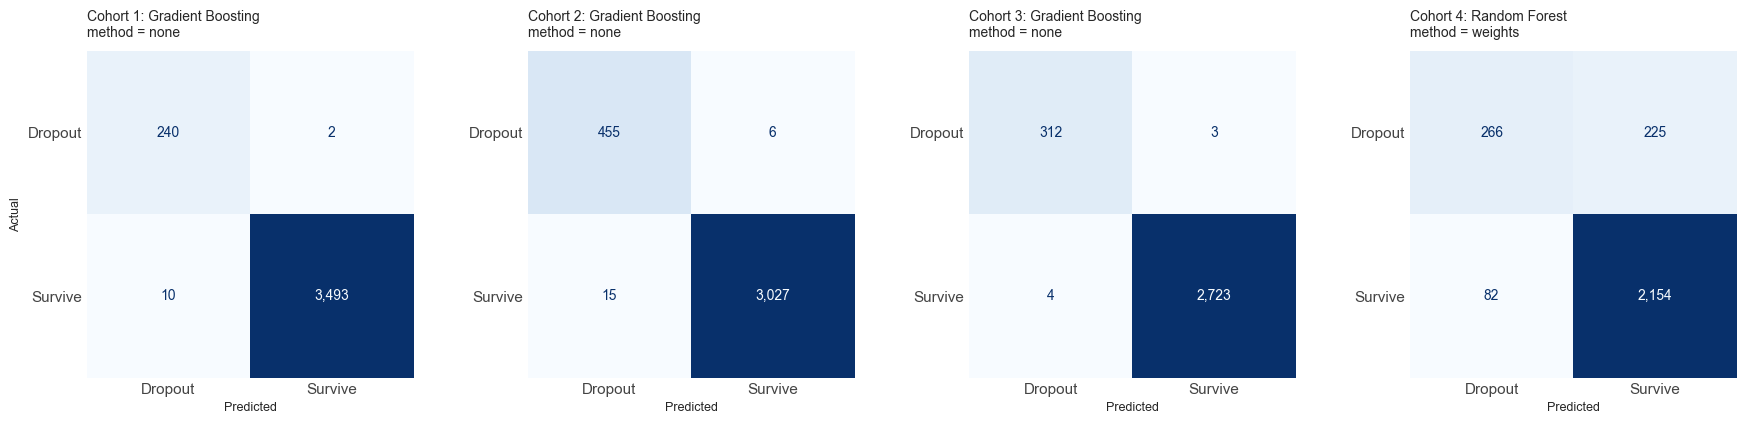

In [37]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))

for i, ax in enumerate(axes, start=1):
    r = final[i]
    wm, wmeth = WINNERS[i]

    ConfusionMatrixDisplay(r['_cm'], display_labels=['Dropout', 'Survive']).plot(
        ax=ax, colorbar=False, cmap='Blues', values_format=',d')

    ax.set_title(f'Cohort {i}: {wm}\nmethod = {wmeth}', fontsize=10, pad=10, loc='left')
    ax.set_xlabel('Predicted', fontsize=9)
    ax.set_ylabel('Actual' if i == 1 else '', fontsize=9)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0, colors='#444444')
    for text in ax.texts:
        text.set_fontsize(10)

plt.tight_layout()
plt.savefig(FIG_DIR / 'confusion_matrices_eng.png', dpi=200, bbox_inches='tight')
plt.show()

### Reading the headline results

| Cohort | Winner | Method | Test F1 | ROC-AUC | Precision | Recall |
|---|---|---|---|---|---|---|
| 1 | Gradient Boosting (tuned) | none | 0.976 | 1.000 | 0.960 | 0.992 |
| 2 | Gradient Boosting (tuned) | none | 0.977 | 1.000 | 0.968 | 0.987 |
| 3 | Gradient Boosting (tuned) | none | 0.989 | 1.000 | 0.987 | 0.990 |
| 4 | Random Forest (tuned) | weights | 0.634 | 0.915 | 0.764 | 0.542 |

Cohorts 1 to 3 are predicted almost perfectly, with recall above 0.97 and precision above 0.96 in each. Cohort 4 remains the outlier, and Section 2.10 examines why.

Tree ensembles win every cohort and Logistic Regression comes last in all four. Whether that is because dropout risk lies in combinations of behaviours rather than in any single one is a question the feature importances in Section 2.9 speak to; the results here establish only the ranking. Cohort 4 is the one cohort a forest holds, and the one that needs class weights, both symptoms of the same weak signal.

A ROC-AUC of 1.000 in three of four cohorts is a result to interrogate rather than to celebrate. These figures rest heavily on the amortised engagement columns and the whole-number pattern of Section 2.2, and Section 2.8 measures how much.

## 2.7 Seed stability

Two checks follow. This section asks whether each winning score survives a change of random seed; Section 2.8 asks how much of it rests on the amortised engagement features.

Each cohort's winning model and method, with its tuned hyperparameters, is refitted under three seeds. Each seed re-draws the train/test split and re-seeds every stochastic step, and the spread in test F1 is reported. Variation of a point or two between runs is ordinary; a large spread would point to a problem in the implementation rather than to a property of the data.

In [38]:
SEEDS = [42, 7, 123]


def eval_at_seed(df, target_col, model_name, method, params, seed):
    # Refit the winning model+method (with tuned params) under a different seed.
    X = df.drop(columns=[target_col])
    y = df[target_col]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE,
                                              random_state=seed, stratify=y)
    pipe = make_pipeline(model_name, method)
    if params:
        pipe.set_params(**params)
    for step in pipe.named_steps.values():          # reseed SMOTE / classifier
        if hasattr(step, 'random_state'):
            step.set_params(random_state=seed)
    pipe.fit(X_tr, y_tr)
    return float(f1_score(y_te, pipe.predict(X_te), pos_label=0, zero_division=0))


rows = []
for i in range(1, 5):
    wm, wmeth = WINNERS[i]
    params = tuned[i]['best_params']
    f1s = [run_or_load(
        # '_tunedall' in the tag encodes WHICH hyperparameters were used: it marks these
        # runs as using the tuned-every-model params, so a retune cannot silently reuse
        # the old seed runs.
        f'seed_c{i}_{s}_tunedall',
        lambda ci=i, m=wm, t=wmeth, p=params, ss=s: eval_at_seed(cohorts_eng[ci], TARGETS[ci], m, t, p, ss)
    ) for s in SEEDS]
    rows.append({'Cohort': f'Cohort {i}', 'Model': wm, 'Method': wmeth,
                 **{f'F1 (seed {s})': round(f, 3) for s, f in zip(SEEDS, f1s)},
                 'Spread': round(max(f1s) - min(f1s), 3)})

seed_df = pd.DataFrame(rows).set_index('Cohort')
print(seed_df.to_string())
seed_df.to_csv(TABLE_DIR / 'seed_stability.csv')
print('\nSaved: outputs/tables/seed_stability.csv')

                      Model   Method  F1 (seed 42)  F1 (seed 7)  F1 (seed 123)  Spread
Cohort                                                                                
Cohort 1  Gradient Boosting     none         0.976        0.967          0.971   0.008
Cohort 2  Gradient Boosting     none         0.977        0.983          0.979   0.005
Cohort 3  Gradient Boosting     none         0.989        0.987          0.984   0.005
Cohort 4      Random Forest  weights         0.634        0.601          0.605   0.033

Saved: outputs/tables/seed_stability.csv


### What the seed check showed

The spread in test F1 across the three seeds is 0.008, 0.005, 0.005 and 0.033 for Cohorts 1 to 4. The check refits each cohort's selected winner under each seed rather than re-running the whole selection, so it speaks to the stability of that model's score, not to whether the same model would win again. Cohorts 1 to 3 vary by less than a point, well inside ordinary run-to-run movement, with no sign of the large swing that would indicate an implementation problem.

Cohort 4's 0.033 is the widest, which follows from its weak signal: at a test F1 of 0.634 the classes do not separate cleanly, so re-drawing the split moves the score more than it does elsewhere. That spread also exceeds, by more than three times, the 0.010 margin by which the random forest was selected over gradient boosting in Section 2.5. The selection there took the maximum, as it should, but the seed check does not confirm that the ordering would hold on a different split. Cohort 4's winner should be read as one of two closely matched candidates rather than as a clear best.

Cohorts 1 to 3 need no such caveat. Their selection and tuning rest on stable ground rather than on a lucky seed.

## 2.8 Does amortised engagement help?

Section 2.2 showed that amortisation encodes a student's eventual lifespan through the whole-number pattern. The features are kept, but their contribution is measured. All five models are re-evaluated with and without the engagement columns, on every cohort.

The comparison reuses each cohort's winning method but not its tuned hyperparameters. Both variants run at default hyperparameters, which keeps the two sides like for like, and it is why the figures here differ from the headline results in Section 2.6.

A positive delta means the engagement columns helped. The delta bounds their combined contribution; it does not separate the behavioural component from the arithmetic one, for the reason given in Section 2.2.

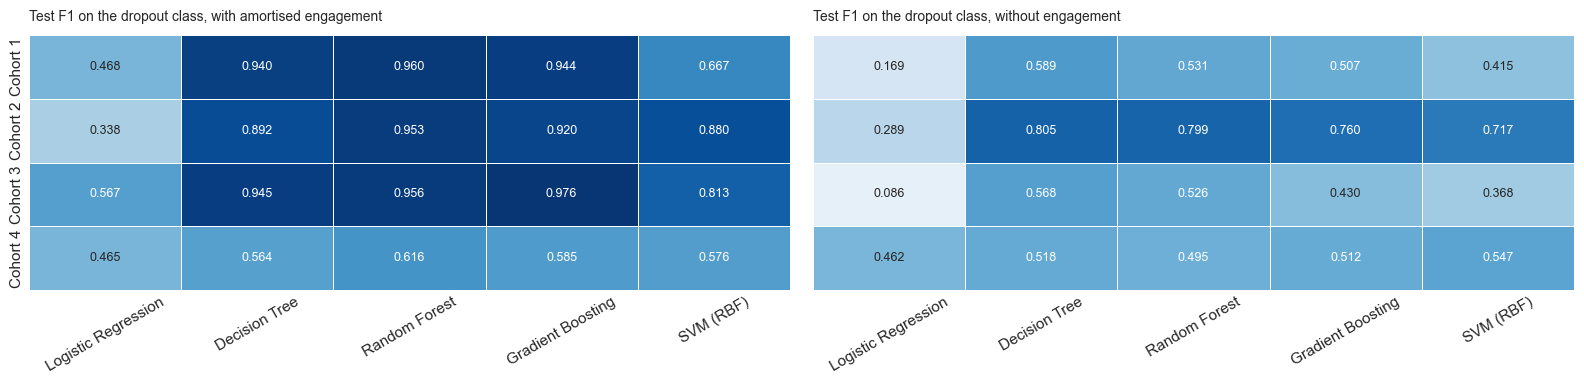

Delta test F1 (engagement minus no-engagement):

          Logistic Regression  Decision Tree  Random Forest  Gradient Boosting  SVM (RBF)
Cohort 1                0.299          0.351          0.429              0.437      0.252
Cohort 2                0.049          0.087          0.154              0.160      0.163
Cohort 3                0.481          0.377          0.430              0.546      0.445
Cohort 4                0.003          0.046          0.121              0.073      0.029

Saved: outputs/figures/heatmap_comparison_eng_vs_noeng.png and delta_eng_vs_noeng.csv


In [39]:
def variant_test_f1(cohorts_dict, variant_tag):
    # Test-set F1 (dropout) for all 5 models under each cohort's WINNING method.
    out = {}
    for i in range(1, 5):
        wmeth = WINNERS[i][1]
        out[i] = {}
        for m in MODEL_NAMES:
            rec = run_or_load(
                f'evn_{variant_tag}_c{i}_{safe(m)}_{wmeth}',
                lambda cd=cohorts_dict, ci=i, mm=m, tt=wmeth: full_eval(cd[ci], TARGETS[ci], mm, tt)
            )
            out[i][m] = rec['F1']
    return out

f1_eng   = variant_test_f1(cohorts_eng,   'eng')
f1_noeng = variant_test_f1(cohorts_noeng, 'noeng')

pivot_eng   = pd.DataFrame(f1_eng).T[MODEL_NAMES]
pivot_noeng = pd.DataFrame(f1_noeng).T[MODEL_NAMES]
pivot_eng.index   = [f'Cohort {i}' for i in pivot_eng.index]
pivot_noeng.index = [f'Cohort {i}' for i in pivot_noeng.index]

fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)

for ax, (title, piv) in zip(axes, [('with amortised engagement', pivot_eng),
                                   ('without engagement', pivot_noeng)]):
    sns.heatmap(piv, annot=True, fmt='.3f', cmap='Blues', vmin=0, vmax=1, ax=ax,
                cbar=False, linewidths=0.5, annot_kws={'fontsize': 9})
    ax.set_title(f'Test F1 on the dropout class, {title}', fontsize=10, pad=10, loc='left')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=30, length=0)
    ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.savefig(FIG_DIR / 'heatmap_comparison_eng_vs_noeng.png', dpi=200, bbox_inches='tight')
plt.show()

delta = (pivot_eng - pivot_noeng).round(3)
pivot_eng.to_csv(TABLE_DIR / 'full_results_eng_f1.csv')
pivot_noeng.to_csv(TABLE_DIR / 'full_results_noeng_f1.csv')
delta.to_csv(TABLE_DIR / 'delta_eng_vs_noeng.csv')
print('Delta test F1 (engagement minus no-engagement):\n')
print(delta.to_string())
print('\nSaved: outputs/figures/heatmap_comparison_eng_vs_noeng.png and delta_eng_vs_noeng.csv')

### What the engagement comparison showed

Amortised engagement helps in every cohort and every model; the delta is positive throughout. The lift is largest where Section 2.2 showed the whole-number pattern operating most strongly, in Cohort 3 at +0.546 for Gradient Boosting and +0.481 for Logistic Regression, and Cohort 1 at +0.437 for Gradient Boosting and +0.429 for the Random Forest. It is smallest in Cohort 4, from +0.003 to +0.121.

Cohort 3's Gradient Boosting makes the size concrete: removing three columns costs it 0.546 of test F1, more than half a point. Both sides of that comparison run at default settings on the same split, so the engagement columns are the only thing that differs. Those figures are not the 0.989 reported in Section 2.6, which is the tuned winner and answers a different question. The tuned 0.989 remains the headline result; the gap here is what shows how much of it depends on three columns.

Cohort 4's near-zero deltas fit the account in Section 2.2. Every student in that cohort has the same lifespan, so the amortisation returns each student's total unchanged and the whole-number pattern separates nobody. What remains is whatever ordinary predictive value the engagement totals carry, and the deltas suggest it is small.

The contrast is the finding. Where the amortisation can encode lifespan, the engagement columns are worth up to half a point of F1. Where it cannot, they are worth almost nothing. Section 2.2 sets out why the behavioural and arithmetic contributions to that gap cannot be separated with this data.

## 2.9 Which behaviours flag dropout risk?

For each cohort's winning model, the plots below show feature importances for tree models or absolute coefficients for logistic regression, arranged in a two-by-two grid. Where a winner has no importance measure, such as the SVM, the Random Forest under the same method is shown instead and labelled as such.

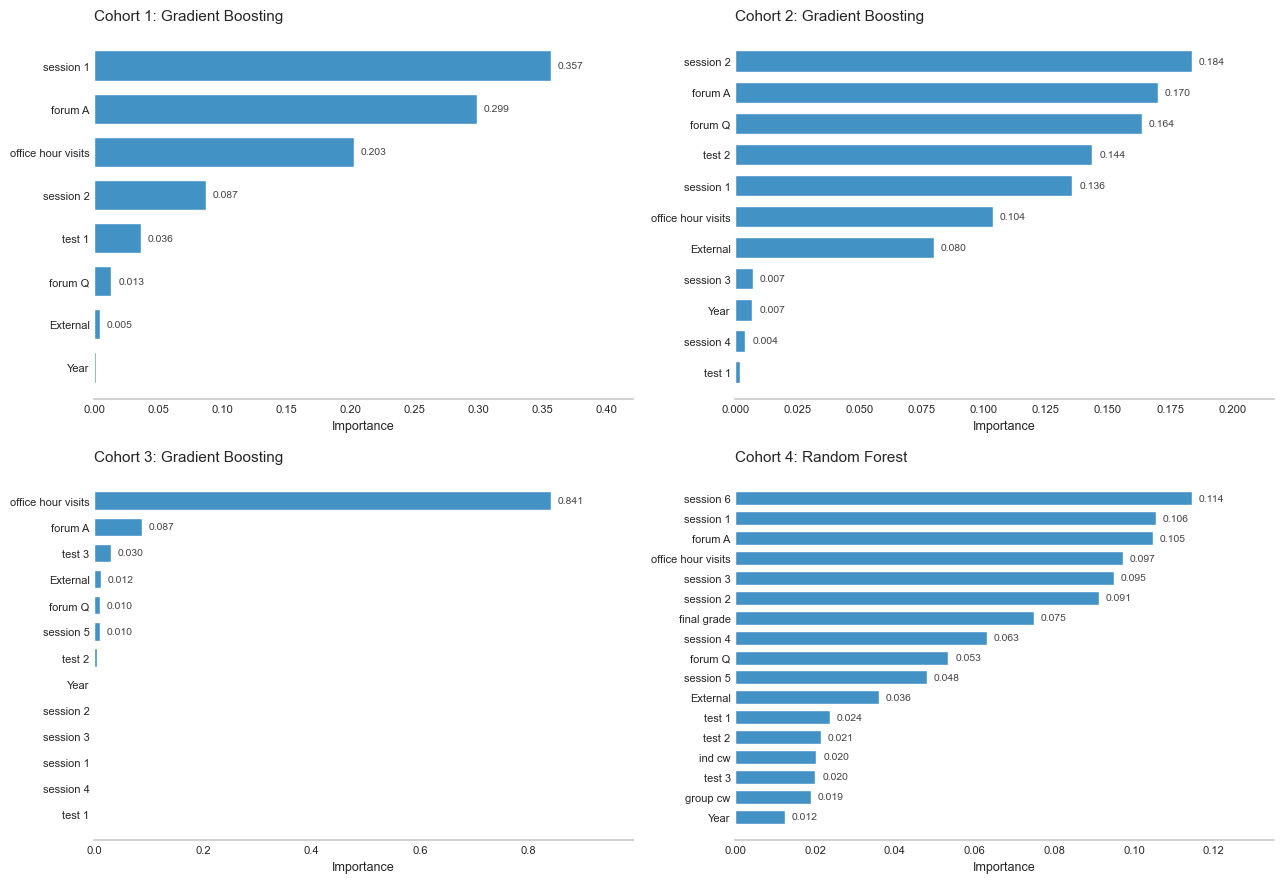

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for i, ax in zip([1, 2, 3, 4], axes.ravel()):
    r = final[i]
    if r['_importances'] is None:
        # Falling back to Random Forest where the winner has no importance measure
        r = run_or_load(
            f'fi_fallback_c{i}',
            lambda ci=i, t=WINNERS[i][1]: full_eval(cohorts_eng[ci], TARGETS[ci], 'Random Forest', t)
        )

    order = np.argsort(r['_importances'])
    names = [r['_features'][j] for j in order]
    values = np.asarray(r['_importances'])[order]

    ax.barh(names, values, color='#4292c6', height=0.7)
    ax.set_title(f'Cohort {i}: {r["Model"]}', fontsize=11, pad=10, loc='left')
    ax.set_xlabel('Importance', fontsize=9)
    ax.set_xlim(0, values.max() * 1.18)
    ax.tick_params(axis='y', labelsize=8, length=0)
    ax.tick_params(axis='x', labelsize=8, length=0)
    ax.grid(False)
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color('#cccccc')

    for y, v in enumerate(values):
        if v > values.max() * 0.01:
            ax.text(v + values.max() * 0.015, y, f'{v:.3f}',
                    va='center', fontsize=7.5, color='#444444')

plt.tight_layout()
plt.savefig(FIG_DIR / 'feature_importances_all_cohorts.png', dpi=200, bbox_inches='tight')
plt.show()

### What the importance charts show

Cohort 1 leans on early attendance at session 1 (0.357) together with the amortised engagement features forum A (0.299) and office hour visits (0.203). The Test 1 grade itself is minor at 0.036, so the split is made on attendance and forum activity rather than on assessed performance. Test 1 is populated for every student in this cohort, so the low weight is a result and not an absence.

Cohort 2 spreads its weight far more evenly: `session 2` (0.184), `forum A` (0.170), `forum Q` (0.164), `test 2` (0.144), `session 1` (0.136) and `office hour visits` (0.104). No single feature dominates, and the newest test grade enters the top four for the first time.

Cohort 3 is dominated by a single feature. `office hour visits` reaches 0.841, nearly ten times `forum A` at 0.087, with `test 3` at 0.030 and everything else below 0.013. This is the same cohort where the whole-number rule of Section 2.2 scores F1 0.939 and where removing the engagement columns costs 0.546 F1 in Section 2.8. Three separate measurements point at the same three columns, and this one narrows the weight to a single one.

Cohort 4 distributes importance more evenly than any other cohort, with `session 6` (0.114), `session 1` (0.106), `forum A` (0.105) and `office hour visits` (0.097) close together and a long tail below. It is the only cohort in which coursework and final grade appear at all, since they exist only in its feature set. Section 2.10 takes up why it remains the hardest cohort despite having the most features.

The ranking moves between cohorts rather than staying fixed. `session 1` leads Cohort 1 and falls to fifth in Cohort 2. `office hour visits` runs third, sixth, first by a wide margin, then fourth. `forum A` is the only feature in the top three of every cohort. What predicts dropout is not constant across the course.

## 2.10 Cohort 4: the administrative dropouts

Cohort 4's target separates the 2,455 administrative dropouts from the 11,177 who certified. Both groups sat every test, submitted both pieces of coursework and received a final grade, so completion itself does not distinguish them. Their behaviour during the course does. Section 1.8 shows the two groups level through sessions 3 and 4 and diverging from session 5, the administrative dropouts falling to 39.5% of session 6 while the certifying group rises to 53.1%. That is the period `session 6` covers, and it is Cohort 4's highest-weighted feature at 0.114. What separates the groups is a decline, not an absence.

Two things follow. The dataset holds no payment or financial variable, so the decision this cohort predicts is made on information the data does not contain. And Cohort 4 is the one cohort where every student has the same lifespan, so the amortisation pattern of Section 2.2 separates nobody and the engagement columns are worth almost nothing here, as the near-zero deltas in Section 2.8 show. Cohorts 1 to 3 have an artefact carrying them; Cohort 4 has only behaviour.

Cohort 4 has the lowest F1 of the four and the most trustworthy basis for it. Cohorts 1 to 3 have the whole-number artefact of Section 2.2 inflating them; Cohort 4 does not, so what it scores it scores on behaviour. The confusion matrix and precision-recall curves below, for all five models under Cohort 4's winning method, show where the prediction breaks down.

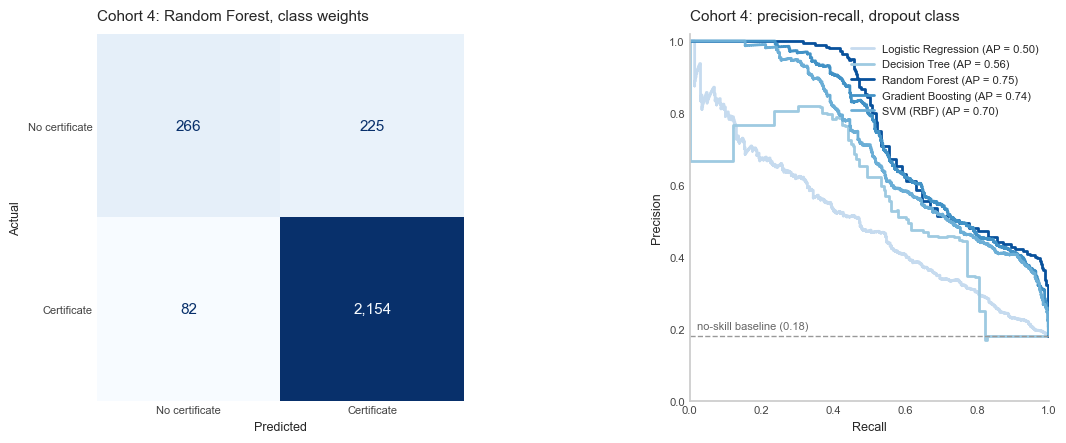

In [41]:
X_tr4, X_te4, y_tr4, y_te4 = split_cohort(cohorts_eng[4], TARGETS[4])
wmeth4 = WINNERS[4][1]
PR_COLOURS = ['#c6dbef', '#9ecae1', '#08519c', '#4292c6', '#6baed6']

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

r4 = final[4]
ConfusionMatrixDisplay(r4['_cm'], display_labels=['No certificate', 'Certificate']).plot(
    ax=axes[0], colorbar=False, cmap='Blues', values_format=',d')
axes[0].set_title(f'Cohort 4: {WINNERS[4][0]}, class weights', fontsize=11, pad=10, loc='left')
axes[0].set_xlabel('Predicted', fontsize=9)
axes[0].set_ylabel('Actual', fontsize=9)
for text in axes[0].texts:
    text.set_fontsize(11)

for m, colour in zip(MODEL_NAMES, PR_COLOURS):
    rec = run_or_load(
        f'evn_eng_c4_{safe(m)}_{wmeth4}',
        lambda mm=m: full_eval(cohorts_eng[4], TARGETS[4], mm, wmeth4)
    )
    PrecisionRecallDisplay.from_predictions(
        (y_te4 == 0).astype(int), -rec['_scores'], name=m, ax=axes[1],
        color=colour, lw=2)

baseline = (y_te4 == 0).mean()
axes[1].axhline(baseline, color='#999999', ls='--', lw=1)
axes[1].text(0.02, baseline + 0.02, f'no-skill baseline ({baseline:.2f})',
             fontsize=8, color='#666666')

axes[1].set_title('Cohort 4: precision-recall, dropout class', fontsize=11, pad=10, loc='left')
axes[1].set_xlabel('Recall', fontsize=9)
axes[1].set_ylabel('Precision', fontsize=9)
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)
axes[1].legend(fontsize=8, loc='upper right', frameon=False)

for ax in axes:
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0, colors='#444444', labelsize=8)
for side in ['bottom', 'left']:
    axes[1].spines[side].set_visible(True)
    axes[1].spines[side].set_color('#cccccc')

plt.tight_layout()
plt.savefig(FIG_DIR / 'cohort4_detailed_eval.png', dpi=200, bbox_inches='tight')
plt.show()

In [42]:
# What Cohort 4's class weights bought: the same tuned Random Forest, searched over the same
# grid on the same folds, with and without the correction. Both pipelines are read back from
# Section 2.5's searches, so this is a like-for-like comparison.
c4_rows = []
for meth in TUNED_METHODS:
    pipe4 = run_or_load(
        f'tuned_c4_{meth}_random_forest',
        lambda mt=meth: tune_combo(cohorts_eng[4], TARGETS[4], 'Random Forest', mt)
    )['best_pipe']
    rec = run_or_load(
        f'final_c4_random_forest_{meth}_tunedall',
        lambda mt=meth, p=pipe4: full_eval(cohorts_eng[4], TARGETS[4], 'Random Forest', mt, pipe=p)
    )
    cm = rec['_cm']
    c4_rows.append({'Method':       meth,
                    'Caught':       int(cm[0, 0]),
                    'Missed':       int(cm[0, 1]),
                    'False alarms': int(cm[1, 0]),
                    'Precision':    rec['Precision'],
                    'Recall':       rec['Recall'],
                    'F1':           rec['F1']})

c4_weights_df = pd.DataFrame(c4_rows).set_index('Method')
print('Cohort 4, tuned Random Forest, with and without class weights (test split):\n')
print(c4_weights_df.to_string())
c4_weights_df.to_csv(TABLE_DIR / 'cohort4_class_weights.csv')
print('\nSaved: outputs/tables/cohort4_class_weights.csv')

Cohort 4, tuned Random Forest, with and without class weights (test split):

         Caught  Missed  False alarms  Precision  Recall     F1
Method                                                         
none        225     266            25      0.900   0.458  0.607
weights     266     225            82      0.764   0.542  0.634

Saved: outputs/tables/cohort4_class_weights.csv


### What Cohort 4 showed

Of 491 administrative dropouts in the test split the winning model catches 266, a recall of 0.542, while raising 82 false alarms, a precision of 0.764. ROC-AUC is 0.915 and PR-AUC 0.764. Clearly better than chance, and still finding only about half.

Class weights are doing visible work. The table above sets the same tuned Random Forest side by side with and without the correction. Without weights the forest is far more cautious: 225 caught for 25 false alarms, precision 0.900 and recall 0.458. With weights, 266 caught for 82, precision 0.764 and recall 0.542. Weighting buys 41 more at-risk students at the cost of 57 more false alarms, and lifts F1 from 0.607 to 0.634. For a retention tool that is the better trade, and it is the direction Section 2.3 argues for, since a missed at-risk student costs more than an unnecessary contact.

Precision of 0.764 with recall of 0.542 is a particular shape: when the model flags a student it is usually right, but it declines to flag nearly half of them. That is consistent with the administrative dropouts dividing into a subset the recorded behaviour distinguishes and a subset it does not, though nothing here establishes what separates the two. Testing that would require comparing the caught and missed groups directly, which this notebook does not do.

The sentence for the report is therefore not that Cohort 4 cannot be predicted. It is that behavioural data identifies a clearly marked subset of administrative dropouts and misses the rest, and that the dataset contains no financial variable that might account for the remainder.

Read the counts with Section 2.7's seed check in mind. Cohort 4's F1 varies by 0.033 across three seeds, more than any other cohort, so the exact counts would move on a different split even though the shape of the result holds.

## 2.11 Saving the winning models

Each cohort's winning fitted pipeline is saved, including its own preprocessing and scaling where relevant. SMOTE is a training-time step and does not affect inference, so the saved objects predict directly.

They cannot be applied to a student mid-course, however. Cohorts 1 to 3 take amortised engagement columns as inputs, and computing those requires the student's lifespan, which is the thing being predicted. The saved models are retrospective analysis tools. An operational early-warning system would need engagement recorded with timestamps, so that activity to date could be measured without reference to how long the student eventually stays.

In [43]:
for i in range(1, 5):
    wm, wmeth = WINNERS[i]
    r = final[i]
    path = MODEL_DIR / f'cohort_{i}_best_{safe(wm)}.pkl'
    joblib.dump(r['_pipe'], path)
    print(f'Cohort {i}  {wm:<20} method={wmeth:<8} {r["Chosen"]:<7} '
          f'F1={r["F1"]:.3f}  ROC-AUC={r["ROC-AUC"]:.3f}  -> {path}')

Cohort 1  Gradient Boosting    method=none     tuned   F1=0.976  ROC-AUC=1.000  -> models/cohort_1_best_gradient_boosting.pkl
Cohort 2  Gradient Boosting    method=none     tuned   F1=0.977  ROC-AUC=1.000  -> models/cohort_2_best_gradient_boosting.pkl
Cohort 3  Gradient Boosting    method=none     tuned   F1=0.989  ROC-AUC=1.000  -> models/cohort_3_best_gradient_boosting.pkl
Cohort 4  Random Forest        method=weights  tuned   F1=0.634  ROC-AUC=0.915  -> models/cohort_4_best_random_forest.pkl


## Summary

What this notebook produced:

1. Screened three class-imbalance methods at library defaults and carried the two that held up into tuning.
2. Tuned all five models in full under each of those methods, in every cohort.
3. Selected each cohort's winner as the highest cross-validated F1 on the dropout class, using the training split only.
4. Reported each winner on a held-out test split touched at no earlier point: F1 0.976, 0.977, 0.989 and 0.634.
5. Refitted each winner under three seeds, giving F1 spreads of 0.008, 0.005, 0.005 and 0.033.
6. Compared every model with and without the amortised engagement columns, in every cohort.
7. Plotted feature importances for each winner and traced how the ranking moves between cohorts.
8. Saved the four winning pipelines to `models/`.

Gradient Boosting with no imbalance correction wins Cohorts 1 to 3; Random Forest with class weights wins Cohort 4. Tuning changes the ranking, so a comparison at library defaults would have ranked scikit-learn's defaults rather than the model families. The Cohort 1 to 3 scores rest heavily on the amortised engagement columns, which Section 2.2 shows encode a student's eventual lifespan as well as their behaviour. Cohort 4 catches 266 of 491 administrative dropouts. It has the lowest F1 of the four and the most trustworthy basis for it, since no artefact is carrying it.

No imputation, `dropout` never used as a feature, one fixed seed of 42 throughout, and the test split touched only at final scoring.

### Handover to Phase 3

Phase 3 takes an unsupervised angle. It groups students into personas from their engagement and performance at entry, using Cohort 1 features only, then tracks how the persona mix shifts from Cohort 1 to Cohort 4.